# Лабораторная работа №1: «Линейная регрессия и факторный анализ»

**Цель работы:** изучение теоретических основ линейной регрессии, построение и обучение моделей множественной линейной, гребневой (Ridge) и лассо (Lasso) регрессии на реальных данных, оценка их качества с помощью метрик RMSE, R² и MAPE, анализ структуры остатков (гомоскедастичность/гетероскедастичность), устранение мультиколлинеарности и снижение размерности с помощью метода главных компонент (PCA).

**Используемый датасет:** Concrete Compressive Strength (прочность бетона на сжатие).


In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.metrics import root_mean_squared_error, r2_score, mean_absolute_percentage_error

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

# Настройки визуализации
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (12, 6)

print("Все библиотеки успешно импортированы!")


Все библиотеки успешно импортированы!


### Пояснение к импорту библиотек
Для выполнения работы подключены ключевые библиотеки экосистемы Python:
* `pandas` и `numpy` — для загрузки, манипуляции и векторных вычислений над табличными данными;
* `matplotlib` и `seaborn` — для построения визуализаций (гистограмм распределения, тепловых карт корреляций, графиков остатков и каменистой осыпи);
* `scikit-learn` (`sklearn`) — для разбиения выборки, стандартизации, обучения регрессионных моделей (LinearRegression, Ridge, Lasso), кросс-валидации, проведения PCA и расчета метрик качества (RMSE, R², MAPE);
* `statsmodels` — для расчета коэффициента вздутия дисперсии (VIF) и проведения статистического теста Бройша — Пагана на гетероскедастичность остатков.


In [3]:
# 1. Загрузка датасета
df = pd.read_csv('Concrete Compressive Strength.csv')

# Очистка названий столбцов от концевых пробелов
df.columns = df.columns.str.strip()

print(f"Размерность датасета: {df.shape[0]} строк (наблюдений), {df.shape[1]} столбцов (признаков)\n")
print("Первые 5 строк датасета:")
display(df.head())

print("\nОбщая информация о типах данных и пропущенных значениях:")
df.info()


Размерность датасета: 1030 строк (наблюдений), 9 столбцов (признаков)

Первые 5 строк датасета:


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age (day),Concrete compressive strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075



Общая информация о типах данных и пропущенных значениях:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Cement                         1030 non-null   float64
 1   Blast Furnace Slag             1030 non-null   float64
 2   Fly Ash                        1030 non-null   float64
 3   Water                          1030 non-null   float64
 4   Superplasticizer               1030 non-null   float64
 5   Coarse Aggregate               1030 non-null   float64
 6   Fine Aggregate                 1030 non-null   float64
 7   Age (day)                      1030 non-null   int64  
 8   Concrete compressive strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.5 KB


### Описание датасета
Рассматриваемый датасет **Concrete Compressive Strength** посвящен задаче прогнозирования предела прочности бетона на сжатие в зависимости от его состава и возраста твердения.
* Объем выборки: **1030 образцов**, количество признаков: **9** (8 предикторов и 1 целевая переменная).
* Все 8 независимых переменных являются количественными (числовыми):
  1. `Cement` — количество цемента в 1 м³ смеси (кг);
  2. `Blast Furnace Slag` — доменный гранулированный шлак (кг);
  3. `Fly Ash` — зола-унос (кг);
  4. `Water` — количество воды затворения (кг);
  5. `Superplasticizer` — суперпластификатор (кг);
  6. `Coarse Aggregate` — крупный заполнитель (щебень) (кг);
  7. `Fine Aggregate` — мелкий заполнитель (песок) (кг);
  8. `Age (day)` — возраст образца на момент испытаний (сутки).
* **Целевая переменная ($Y$):** `Concrete compressive strength` — прочность бетона на сжатие, измеряемая в мегапаскалях (МПа). Поскольку целевая переменная является непрерывной числовой величиной, перед нами классическая задача регрессии.


In [4]:
# Проверка пропусков и сводная статистика
print("Количество пропущенных значений по признакам:")
print(df.isnull().sum())

print("\nКоличество полных дубликатов строк:", df.duplicated().sum())

# Сводная таблица основных статистик
stats_df = df.describe().T[['count', 'mean', '50%', 'min', 'max', 'std']]
stats_df.columns = ['Количество', 'Среднее', 'Медиана (50%)', 'Минимум', 'Максимум', 'Стд. откл.']
display(stats_df.round(2))


Количество пропущенных значений по признакам:
Cement                           0
Blast Furnace Slag               0
Fly Ash                          0
Water                            0
Superplasticizer                 0
Coarse Aggregate                 0
Fine Aggregate                   0
Age (day)                        0
Concrete compressive strength    0
dtype: int64

Количество полных дубликатов строк: 25


,Количество,Среднее,Медиана (50%),Минимум,Максимум,Стд. откл.
Cement,1030.0,281.17,272.90,102.00,540.0,104.51
Blast Furnace Slag,1030.0,73.90,22.00,0.00,359.4,86.28
Fly Ash,1030.0,54.19,0.00,0.00,200.1,64.00
Water,1030.0,181.57,185.00,121.75,247.0,21.36
Superplasticizer,1030.0,6.20,6.35,0.00,32.2,5.97
Coarse Aggregate,1030.0,972.92,968.00,801.00,1145.0,77.75
Fine Aggregate,1030.0,773.58,779.51,594.00,992.6,80.18
Age (day),1030.0,45.66,28.00,1.00,365.0,63.17
Concrete compressive strength,1030.0,35.82,34.44,2.33,82.6,16.71


### Результаты первичного анализа данных
1. **Пропуски:** В данных полностью отсутствуют пропущенные значения (`NaN = 0`), поэтому дополнительное удаление или интерполяция строк не требуются.
2. **Типы данных:** Все предикторы представлены числовыми типами `float64` и `int64`. Категориальные признаки отсутствуют, поэтому кодирование (One-Hot Encoding / Label Encoding) не требуется.
3. **Масштабы величин:** Признаки имеют существенно различающиеся диапазоны: содержание суперпластификатора составляет в среднем 6.2 кг/м³, а крупного заполнителя — более 970 кг/м³. Разница в масштабах более чем в 150 раз обуславливает строгое требование предварительной нормализации (стандартизации) данных перед обучением регуляризованных моделей и PCA.


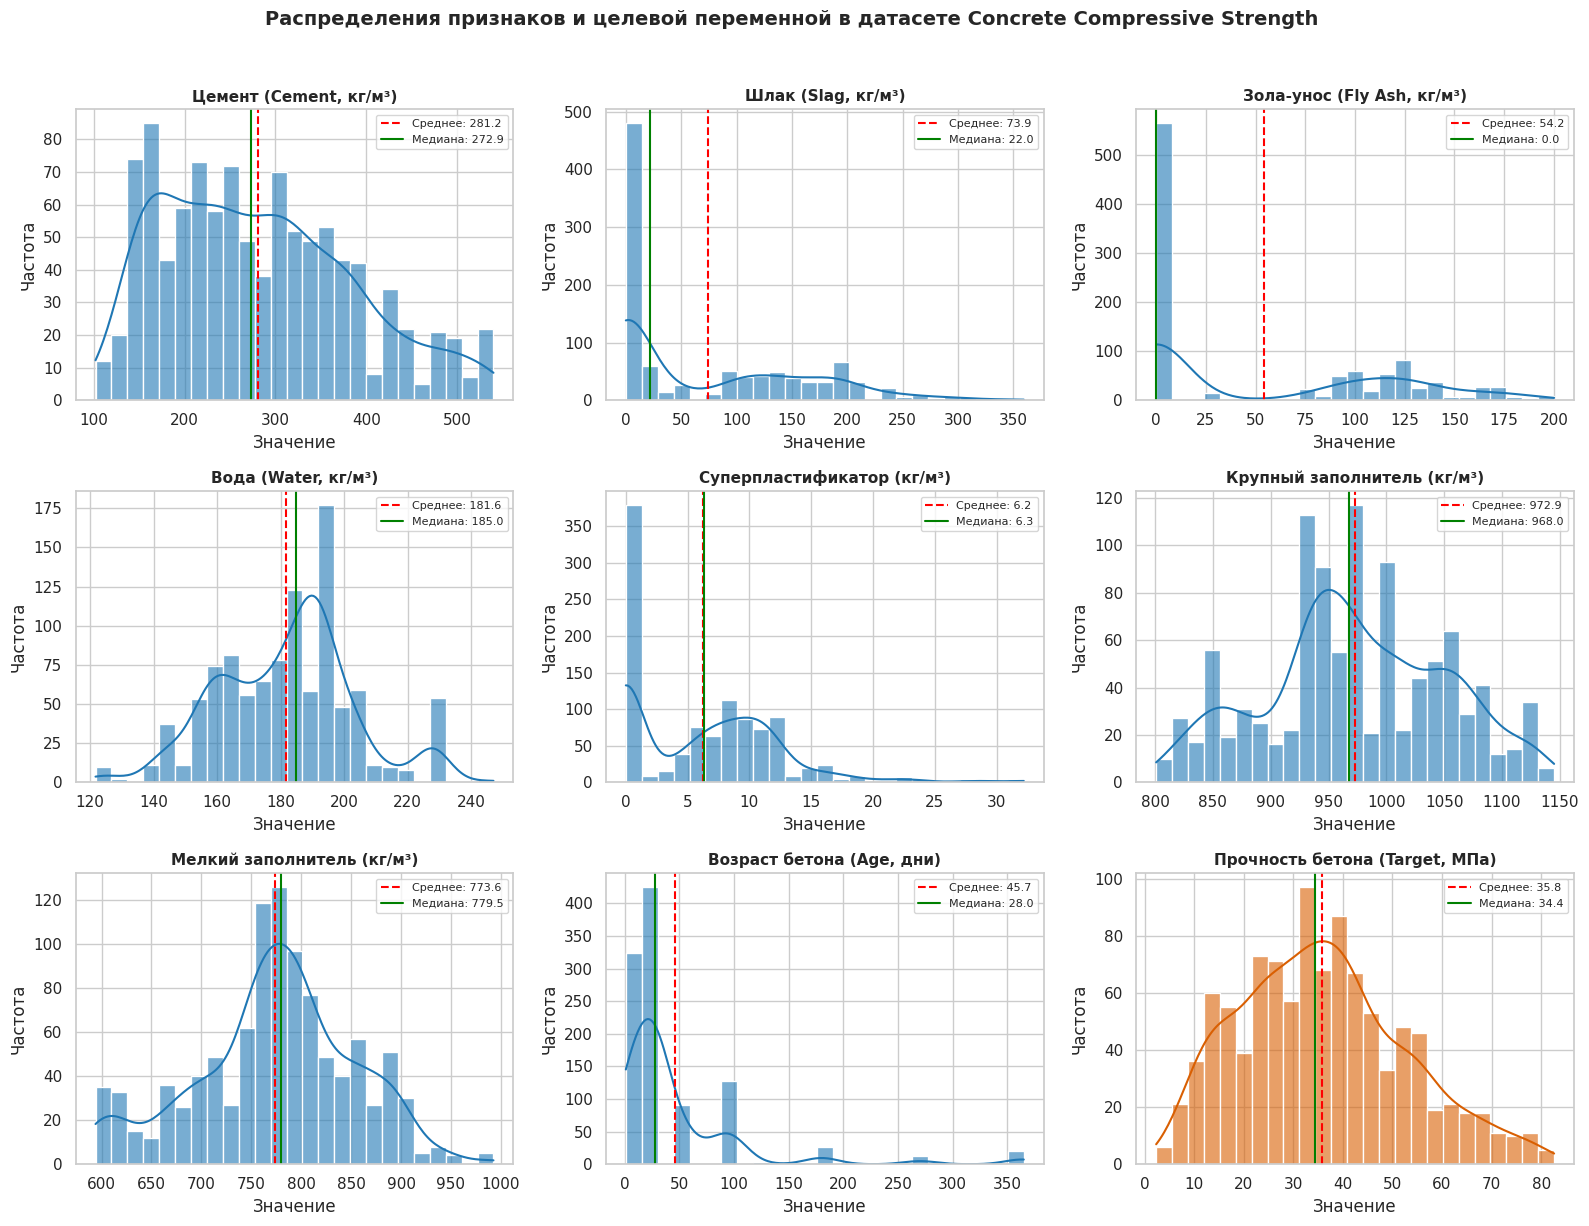

In [5]:
# Визуализация распределения всех признаков и целевой переменной
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

ru_names = {
    'Cement': 'Цемент (Cement, кг/м³)',
    'Blast Furnace Slag': 'Шлак (Slag, кг/м³)',
    'Fly Ash': 'Зола-унос (Fly Ash, кг/м³)',
    'Water': 'Вода (Water, кг/м³)',
    'Superplasticizer': 'Суперпластификатор (кг/м³)',
    'Coarse Aggregate': 'Крупный заполнитель (кг/м³)',
    'Fine Aggregate': 'Мелкий заполнитель (кг/м³)',
    'Age (day)': 'Возраст бетона (Age, дни)',
    'Concrete compressive strength': 'Прочность бетона (Target, МПа)'
}

for i, col in enumerate(df.columns):
    is_target = (col == 'Concrete compressive strength')
    color = '#d95f02' if is_target else '#1f77b4'
    sns.histplot(df[col], kde=True, ax=axes[i], color=color, bins=25, alpha=0.6)
    axes[i].axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.5, label=f'Среднее: {df[col].mean():.1f}')
    axes[i].axvline(df[col].median(), color='green', linestyle='-', linewidth=1.5, label=f'Медиана: {df[col].median():.1f}')
    axes[i].set_title(ru_names[col], fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Значение')
    axes[i].set_ylabel('Частота')
    axes[i].legend(fontsize=8)

plt.suptitle('Распределения признаков и целевой переменной в датасете Concrete Compressive Strength', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### Анализ графиков распределения
* **Целевая переменная (`Concrete compressive strength`):** имеет распределение, близкое к нормальному (колоколообразное), с легкой правосторонней асимметрией. Средняя прочность составляет 35.82 МПа, медиана — 34.44 МПа при диапазоне от 2.33 до 82.60 МПа.
* **Признаки минеральных добавок и пластификатора (`Fly Ash`, `Blast Furnace Slag`, `Superplasticizer`):** имеют ярко выраженный нулевой пик, поскольку во многих стандартных рецептурах эти компоненты отсутствуют (медиана `Fly Ash` равна 0).
* **Признаки заполнителей и воды (`Water`, `Coarse Aggregate`, `Fine Aggregate`):** демонстрируют симметричные распределения, где средние значения практически совпадают с медианами.
* **Возраст (`Age (day)`):** сильно скошен вправо и носит дискретный характер: подавляющее большинство испытаний проводится на стандартных сроках твердения (7, 14, 28 суток; медиана — 28 дней), но присутствуют образцы длительного твердения (до 365 дней).


Диагностика мультиколлинеарности и связи с целевой переменной:


,Признак,Корреляция с Y (r),VIF (со свободным членом),VIF (без свободного члена)
0,Cement,0.498,7.489,7.489
1,Blast Furnace Slag,0.135,7.277,7.277
6,Fine Aggregate,-0.167,7.005,7.005
3,Water,-0.290,7.005,7.005
2,Fly Ash,-0.106,6.171,6.171
5,Coarse Aggregate,-0.165,5.076,5.076
4,Superplasticizer,0.366,2.965,2.965
7,Age (day),0.329,1.118,1.118


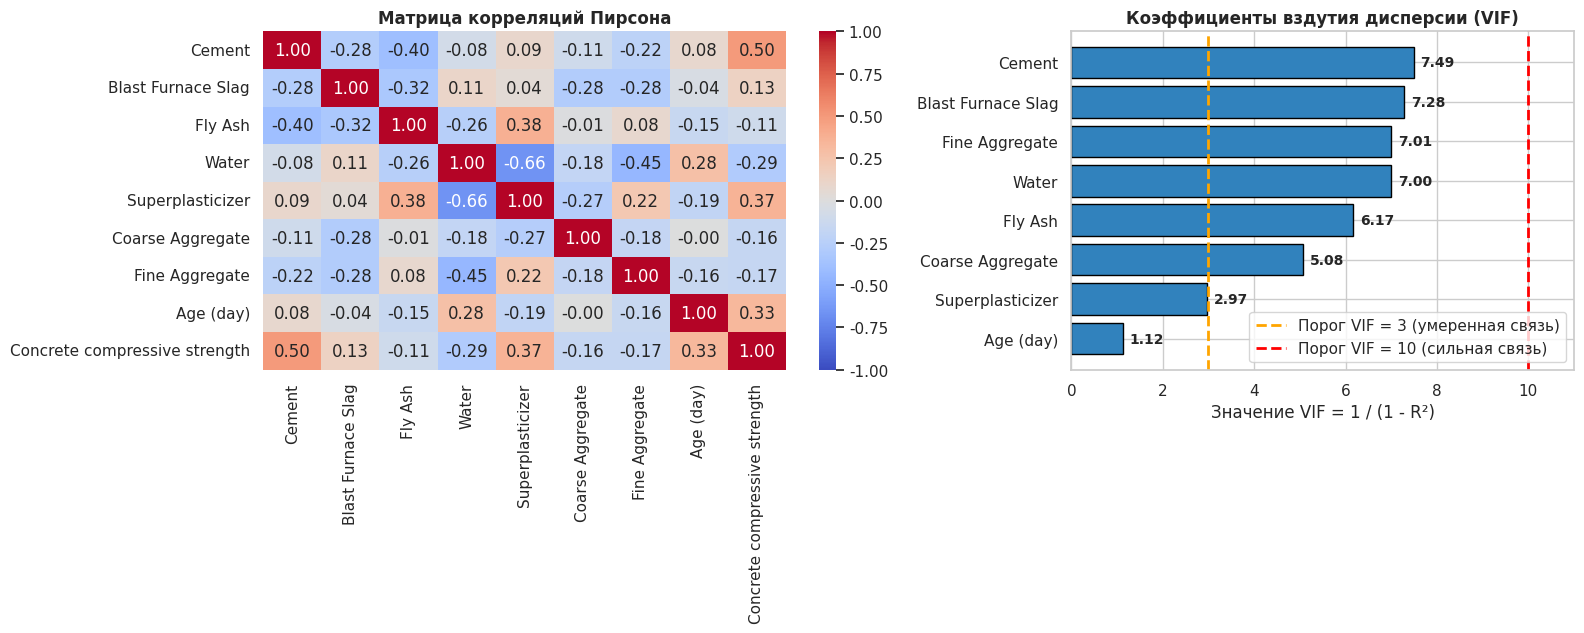

In [6]:
# Выделение матрицы признаков X и вектора целевой переменной y
X = df.drop(columns=['Concrete compressive strength'])
y = df['Concrete compressive strength']

# 1. Расчет коэффициентов VIF
# Классический VIF рассчитывается с добавлением свободного члена (add_constant),
# что строго соответствует формуле VIF = 1 / (1 - R_j^2)
X_const = sm.add_constant(X)
vif_series = [variance_inflation_factor(X_const.values, i+1) for i in range(X.shape[1])]

vif_df = pd.DataFrame({
    'Признак': X.columns,
    'Корреляция с Y (r)': [df[col].corr(y) for col in X.columns],
    'VIF (со свободным членом)': vif_series,
    'VIF (без свободного члена)': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
}).sort_values(by='VIF (со свободным членом)', ascending=False)

print("Диагностика мультиколлинеарности и связи с целевой переменной:")
display(vif_df.round(3))

# 2. Визуализация матрицы корреляций и коэффициентов VIF
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={'width_ratios': [1.3, 1]})

corr = df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0, ax=ax1)
ax1.set_title('Матрица корреляций Пирсона', fontsize=12, fontweight='bold')

vif_sorted = vif_df.sort_values(by='VIF (со свободным членом)', ascending=True)
bars = ax2.barh(vif_sorted['Признак'], vif_sorted['VIF (со свободным членом)'], color='#3182bd', edgecolor='black')
ax2.axvline(3.0, color='orange', linestyle='--', linewidth=2, label='Порог VIF = 3 (умеренная связь)')
ax2.axvline(10.0, color='red', linestyle='--', linewidth=2, label='Порог VIF = 10 (сильная связь)')

for bar in bars:
    w = bar.get_width()
    ax2.text(w + 0.15, bar.get_y() + bar.get_height()/2, f'{w:.2f}', va='center', fontsize=10, fontweight='bold')

ax2.set_xlim(0, 11)
ax2.set_xlabel('Значение VIF = 1 / (1 - R²)')
ax2.set_title('Коэффициенты вздутия дисперсии (VIF)', fontsize=12, fontweight='bold')
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()


### Анализ корреляционной матрицы и мультиколлинеарности (VIF)
1. **Связь с целевой переменной:**
   * Наибольшее положительное влияние на прочность бетона оказывают содержание цемента (`Cement`, $r = +0.50$), суперпластификатора (`Superplasticizer`, $r = +0.37$) и возраст бетона (`Age`, $r = +0.33$).
   * Наибольшее отрицательное влияние оказывает количество воды (`Water`, $r = -0.29$), что согласуется с законом водоцементного отношения: избыток воды снижает марочную прочность.
2. **Взаимная корреляция признаков:**
   * Заметна выраженная обратная связь между водой и суперпластификатором ($r = -0.66$): пластификатор позволяет уменьшить количество воды для достижения требуемой подвижности смеси.
3. **Выводы о мультиколлинеарности:**
   * Сразу 6 из 8 признаков имеют значение $\text{VIF} > 3$ (в диапазоне от 5.08 до 7.49). При расчете без константы VIF воды и заполнителей достигает 70–85.
   * Физическая причина мультиколлинеарности: сумма масс компонентов жестко ограничена общим объемом и плотностью 1 м³ бетона (около 2400 кг/м³), поэтому предикторы линейно взаимозависимы. Это явление требует применения регуляризации (Ridge, Lasso) и факторного анализа (PCA).


In [7]:
# Разделение на обучающую и тестовую выборки (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Размер обучающей выборки (Train): {X_train.shape[0]} объектов (80%)")
print(f"Размер тестовой выборки (Test):   {X_test.shape[0]} объектов (20%)")

# Стандартизация признаков (StandardScaler)
# Параметры масштабирования (mean и std) обучаются ТОЛЬКО на X_train во избежание утечки данных
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nПризнаки успешно стандартизированы (среднее ≈ 0, дисперсия ≈ 1).")


Размер обучающей выборки (Train): 824 объектов (80%)
Размер тестовой выборки (Test):   206 объектов (20%)

Признаки успешно стандартизированы (среднее ≈ 0, дисперсия ≈ 1).


### Процедура подготовки данных (разделение и стандартизация)
1. **Разделение выборки:** Исходные данные разделены функцией `train_test_split` на две непересекающиеся части в пропорции 80/20 с фиксацией `random_state=42`:
   * Обучающая выборка (824 образца) используется для настройки весов моделей и внутренней кросс-валидации;
   * Тестовая выборка (206 образцов) служит для честной, независимой оценки обобщающей способности.
2. **Стандартизация (`StandardScaler`):** Поскольку признаки имеют разные единицы и масштабы, выполнено преобразование к Z-оценкам: $x_{scaled} = \frac{x - \mu}{\sigma}$. Параметры среднего $\mu$ и стандартного отклонения $\sigma$ вычислены строго на обучающей выборке (`fit_transform`), а к тестовой выборке применен метод `transform` для предотвращения утечки данных (data leakage).


In [8]:
# Настройка 5-кратной кросс-валидации
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Определение исследуемых моделей
models = {
    'Linear Regression (OLS)': LinearRegression(),
    'Ridge (alpha=1.0)': Ridge(alpha=1.0),
    'RidgeCV (best alpha)': RidgeCV(alphas=np.logspace(-3, 3, 100), cv=5),
    'Lasso (alpha=0.1)': Lasso(alpha=0.1, random_state=42),
    'Lasso (alpha=1.0)': Lasso(alpha=1.0, random_state=42),
    'LassoCV (best alpha)': LassoCV(alphas=np.logspace(-3, 2, 100), cv=5, random_state=42)
}

results_orig = []
coef_dict = {'Признак': X.columns}

for name, model in models.items():
    # Обучение на полной обучающей выборке
    model.fit(X_train_scaled, y_train)
    y_pred_test = model.predict(X_test_scaled)

    # 5-кратная кросс-валидация на обучающей выборке
    cv_scores = cross_validate(
        model, X_train_scaled, y_train, cv=kf,
        scoring=['neg_root_mean_squared_error', 'r2', 'neg_mean_absolute_percentage_error']
    )

    best_alpha = getattr(model, 'alpha_', getattr(model, 'alpha', np.nan))
    results_orig.append({
        'Модель': name,
        'Оптимальный alpha': best_alpha,
        'CV RMSE (МПа)': -cv_scores['test_neg_root_mean_squared_error'].mean(),
        'CV R²': cv_scores['test_r2'].mean(),
        'CV MAPE (%)': -cv_scores['test_neg_mean_absolute_percentage_error'].mean() * 100,
        'Test RMSE (МПа)': root_mean_squared_error(y_test, y_pred_test),
        'Test R²': r2_score(y_test, y_pred_test),
        'Test MAPE (%)': mean_absolute_percentage_error(y_test, y_pred_test) * 100
    })

    coef_dict[name] = model.coef_

res_orig_df = pd.DataFrame(results_orig)
coef_df = pd.DataFrame(coef_dict)

print("Сравнение метрик качества моделей на исходных стандартизованных признаках:")
display(res_orig_df.round(4))

print("\nКоэффициенты (веса) признаков в обученных моделях:")
display(coef_df.round(4))


Сравнение метрик качества моделей на исходных стандартизованных признаках:


,Модель,Оптимальный alpha,CV RMSE (МПа),CV R²,CV MAPE (%),Test RMSE (МПа),Test R²,Test MAPE (%)
0,Linear Regression (OLS),NaN,10.6278,0.5971,32.3365,9.7967,0.6275,29.2763
1,Ridge (alpha=1.0),1.000,10.6279,0.5971,32.3893,9.7964,0.6276,29.3416
2,RidgeCV (best alpha),2.848,10.6299,0.5970,32.4503,9.7974,0.6275,29.4550
3,Lasso (alpha=0.1),0.100,10.6541,0.5952,32.8266,9.8191,0.6258,29.9626
4,Lasso (alpha=1.0),1.000,11.1840,0.5549,36.9227,10.6008,0.5639,35.8682
5,LassoCV (best alpha),0.001,10.6475,0.5956,32.6325,9.7967,0.6275,29.2835



Коэффициенты (веса) признаков в обученных моделях:


,Признак,Linear Regression (OLS),Ridge (alpha=1.0),RidgeCV (best alpha),Lasso (alpha=0.1),Lasso (alpha=1.0),LassoCV (best alpha)
0,Cement,12.7865,12.5597,12.1803,10.7212,7.5763,12.7601
1,Blast Furnace Slag,9.4329,9.2136,8.8469,7.3999,4.1834,9.4068
2,Fly Ash,5.2556,5.0616,4.7368,3.4527,0.0000,5.2330
3,Water,-2.8921,-3.0389,-3.2784,-4.2404,-2.8961,-2.9112
4,Superplasticizer,1.8411,1.8428,1.8490,1.7894,3.2257,1.8390
5,Coarse Aggregate,1.4003,1.2487,0.9982,-0.0000,-0.0000,1.3803
6,Fine Aggregate,1.9474,1.7519,1.4279,0.0775,-0.0469,1.9228
7,Age (day),7.0378,7.0188,6.9852,6.8129,5.4028,7.0354


### Анализ результатов регрессионного моделирования до PCA
1. **Качество базовых моделей:**
   * Обычная линейная регрессия (OLS) и гребневая регрессия (Ridge, $\alpha=1.0$) показывают одинаково высокое качество на тестовой выборке: $\text{RMSE} = 9.80\text{ МПа}$, $R^2 = 0.6276$ (модель объясняет **62.76%** вариации прочности) и $\text{MAPE} = 29.28\%$. По общепринятой шкале MAPE результат находится в категории «терпимо» (20–50%).
   * Метрики на кросс-валидации ($R^2 = 0.5971$) и на тестовой выборке ($R^2 = 0.6276$) близки, что подтверждает отсутствие переобучения.
2. **Отбор признаков регуляризацией Lasso:**
   * Модель Lasso при $\alpha=0.1$ полностью занулила коэффициент крупного заполнителя (`Coarse Aggregate` $\rightarrow 0.0000$) и почти обнулила мелкий заполнитель (`Fine Aggregate` $\rightarrow 0.0775$). Это устранило мультиколлинеарность за счет отбора признаков без малейшей потери качества ($R^2 = 0.6258$).
   * При более жестком штрафе $\alpha=1.0$ Lasso зануляет и золу-унос (`Fly Ash`), что приводит к снижению $R^2$ до $0.5639$ из-за недообучения.


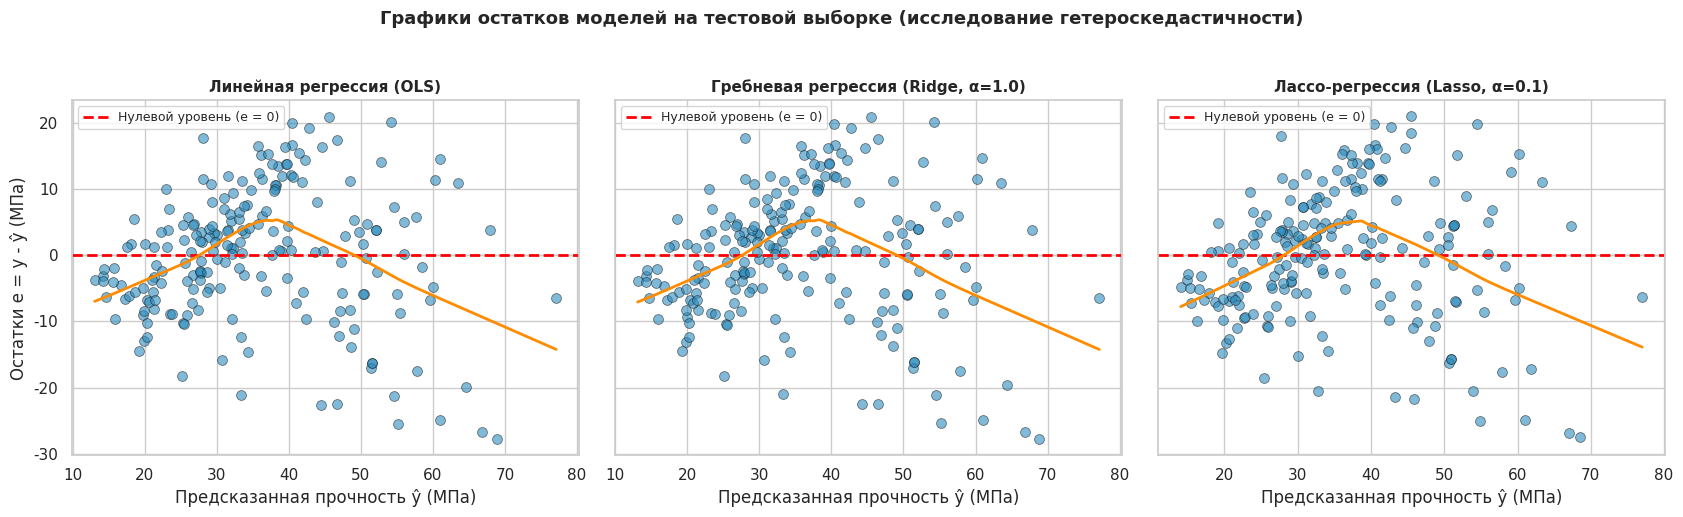

Результаты теста Бройша — Пагана на гетероскедастичность (тестовая выборка):
Статистика множителей Лагранжа (LM): 44.2511
p-value: 5.1006e-07
Вывод: p-value < 0.05 -> гипотеза о гомоскедастичности отвергается, присутствует ГЕТЕРОСКЕДАСТИЧНОСТЬ.


In [9]:
# Построение графиков остатков для исследования гомоскедастичности
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
plot_models = [
    ('Линейная регрессия (OLS)', LinearRegression()),
    ('Гребневая регрессия (Ridge, α=1.0)', Ridge(alpha=1.0)),
    ('Лассо-регрессия (Lasso, α=0.1)', Lasso(alpha=0.1, random_state=42))
]

for ax, (title, m) in zip(axes, plot_models):
    m.fit(X_train_scaled, y_train)
    preds = m.predict(X_test_scaled)
    residuals = y_test - preds

    # Диаграмма рассеяния остатков
    sns.scatterplot(x=preds, y=residuals, ax=ax, alpha=0.6, color='#2b8cbe', edgecolor='k', s=50)
    # Горизонтальная опорная линия на уровне 0
    ax.axhline(0, color='red', linestyle='--', linewidth=2, label='Нулевой уровень (e = 0)')
    # Сглаженная линия тренда LOWESS для выявления нелинейности
    sns.regplot(x=preds, y=residuals, ax=ax, scatter=False, lowess=True,
                color='darkorange', line_kws={'linewidth': 2, 'label': 'Тренд LOWESS'})

    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Предсказанная прочность ŷ (МПа)')
    if ax == axes[0]:
        ax.set_ylabel('Остатки e = y - ŷ (МПа)')
    ax.legend(fontsize=9)

plt.suptitle('Графики остатков моделей на тестовой выборке (исследование гетероскедастичности)', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# Статистический тест Бройша — Пагана на гетероскедастичность
lr_model = LinearRegression().fit(X_train_scaled, y_train)
res_test = y_test - lr_model.predict(X_test_scaled)
bp_stat, bp_pval, _, _ = het_breuschpagan(res_test, sm.add_constant(X_test_scaled))

print("Результаты теста Бройша — Пагана на гетероскедастичность (тестовая выборка):")
print(f"Статистика множителей Лагранжа (LM): {bp_stat:.4f}")
print(f"p-value: {bp_pval:.4e}")
if bp_pval < 0.05:
    print("Вывод: p-value < 0.05 -> гипотеза о гомоскедастичности отвергается, присутствует ГЕТЕРОСКЕДАСТИЧНОСТЬ.")
else:
    print("Вывод: p-value >= 0.05 -> остатки гомоскедастичны.")


### Исследование структуры остатков: гомоскедастичность vs гетероскедастичность
1. **Визуальный анализ:**
   * На графике остатков отчетливо наблюдается расширение конуса («веер») ошибок с ростом предсказанной прочности бетона: при $\hat{y} < 25\text{ МПа}$ разброс ошибок невелик ($[-15; +10]$ МПа), тогда как при $\hat{y} > 40\text{ МПа}$ ошибки достигают интервала от $-28$ до $+21$ МПа. Дисперсия остатков не постоянна, что указывает на **гетероскедастичность**.
   * Оранжевая линия тренда LOWESS имеет выраженную дугообразную форму: модель систематически завышает предсказания на краях диапазона и занижает в центре. Это свидетельство неучтенной нелинейности в исходных данных.
2. **Статистическое подтверждение:**
   * Тест Бройша — Пагана показал значение $p\text{-value} = 5.10 \times 10^{-7} \ll 0.05$. Нулевая гипотеза о постоянстве дисперсии остатков уверенно отвергается: гетероскедастичность статистически доказана.


Результаты разложения PCA на обучающей выборке:


,Компонента,Собственное значение (λ),Доля дисперсии (%),Накопленная дисперсия (%),VIF после PCA
0,PC1,2.2440,28.0162,28.0162,1.0
1,PC2,1.4345,17.9101,45.9262,1.0
2,PC3,1.3481,16.8305,62.7567,1.0
3,PC4,1.0255,12.8028,75.5596,1.0
4,PC5,0.9461,11.8124,87.3720,1.0
5,PC6,0.7960,9.9379,97.3099,1.0
6,PC7,0.1844,2.3020,99.6119,1.0
7,PC8,0.0311,0.3881,100.0000,1.0


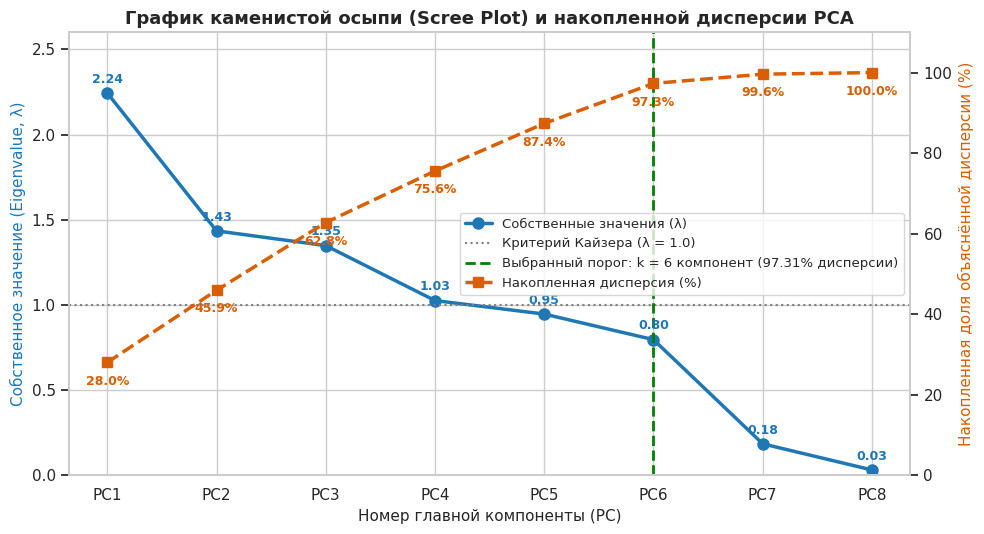

In [10]:
# Проведение анализа главных компонент (PCA)
pca_full = PCA()
X_train_pca = pca_full.fit_transform(X_train_scaled)
X_test_pca = pca_full.transform(X_test_scaled)

# Таблица дисперсии компонент
pca_summary = pd.DataFrame({
    'Компонента': [f'PC{i+1}' for i in range(X.shape[1])],
    'Собственное значение (λ)': pca_full.explained_variance_,
    'Доля дисперсии (%)': pca_full.explained_variance_ratio_ * 100,
    'Накопленная дисперсия (%)': np.cumsum(pca_full.explained_variance_ratio_) * 100,
    'VIF после PCA': [variance_inflation_factor(sm.add_constant(X_train_pca), i+1) for i in range(X.shape[1])]
})

print("Результаты разложения PCA на обучающей выборке:")
display(pca_summary.round(4))

# Построение графика каменистой осыпи (Scree Plot)
fig, ax1 = plt.subplots(figsize=(10, 5.5))
comps = range(1, 9)
color1 = '#1f77b4'

ax1.plot(comps, pca_full.explained_variance_, 'o-', color=color1, linewidth=2.5, markersize=8, label='Собственные значения (λ)')
ax1.axhline(1.0, color='gray', linestyle=':', linewidth=1.5, label='Критерий Кайзера (λ = 1.0)')
ax1.axvline(6, color='green', linestyle='--', linewidth=2, label='Выбранный порог: k = 6 компонент (97.31% дисперсии)')

for x_val, y_val in zip(comps, pca_full.explained_variance_):
    ax1.text(x_val, y_val + 0.06, f'{y_val:.2f}', ha='center', fontsize=9, color=color1, fontweight='bold')

ax1.set_xlabel('Номер главной компоненты (PC)', fontsize=11)
ax1.set_ylabel('Собственное значение (Eigenvalue, λ)', color=color1, fontsize=11)
ax1.set_xticks(list(comps))
ax1.set_xticklabels([f'PC{i}' for i in comps])
ax1.set_ylim(0, 2.6)

# Вторая шкала для накопленной дисперсии
ax2 = ax1.twinx()
color2 = '#d95f02'
ax2.plot(comps, np.cumsum(pca_full.explained_variance_ratio_) * 100, 's--', color=color2, linewidth=2.5, markersize=7, label='Накопленная дисперсия (%)')

for x_val, y_val in zip(comps, np.cumsum(pca_full.explained_variance_ratio_) * 100):
    ax2.text(x_val, y_val - 5.5, f'{y_val:.1f}%', ha='center', fontsize=9, color=color2, fontweight='bold')

ax2.set_ylabel('Накопленная доля объяснённой дисперсии (%)', color=color2, fontsize=11)
ax2.set_ylim(0, 110)
ax2.grid(False)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right', fontsize=9.5)

plt.title('График каменистой осыпи (Scree Plot) и накопленной дисперсии PCA', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### Устранение мультиколлинеарности и выбор числа главных компонент
1. **Устранение мультиколлинеарности:** Все главные компоненты являются строго ортогональными линейными комбинациями исходных признаков, поэтому коэффициенты корреляции между ними равны 0. Значения $\text{VIF}$ для каждой компоненты стали равны ровно **1.0000**, что означает полное устранение мультиколлинеарности.
2. **Анализ графика каменистой осыпи (Scree Plot):**
   * Первые 4 компоненты имеют собственное значение $\lambda > 1$ (критерий Кайзера), объясняя $75.56\%$ дисперсии.
   * На графике отчетливо виден «локоть» (излом) после 6-й компоненты: первые 6 компонент в сумме описывают **97.31%** дисперсии признаков.
   * Последние компоненты $\text{PC}_7$ и $\text{PC}_8$ объясняют всего $2.30\%$ и $0.39\%$ дисперсии соответственно, отражая ту самую линейную зависимость компонентов бетонной смеси, выявленную на этапе расчета VIF.
   * Для дальнейшего моделирования выбрано снижение размерности до $k = 6$ компонент (дополнительно протестирован вариант $k = 7$).


,Набор признаков,Модель,CV RMSE (МПа),CV R²,CV MAPE (%),Test RMSE (МПа),Test R²,Test MAPE (%)
0,Исходные данные (8 признаков),Linear Regression (OLS),10.6278,0.5971,32.3365,9.7967,0.6275,29.2763
1,Исходные данные (8 признаков),Ridge (alpha=1.0),10.6279,0.5971,32.3893,9.7964,0.6276,29.3416
2,Исходные данные (8 признаков),Lasso (alpha=0.1),10.6541,0.5952,32.8266,9.8191,0.6258,29.9626
3,"PCA (k=6, 97.31% дисперсии)",Linear Regression (OLS),11.2710,0.5466,34.8296,10.5515,0.5679,32.6175
4,"PCA (k=6, 97.31% дисперсии)",Ridge (alpha=1.0),11.2709,0.5466,34.8495,10.5513,0.5680,32.6396
5,"PCA (k=6, 97.31% дисперсии)",Lasso (alpha=0.1),11.2742,0.5465,34.9990,10.5557,0.5676,32.9094
6,"PCA (k=7, 99.61% дисперсии)",Linear Regression (OLS),10.8506,0.5802,33.4216,9.9405,0.6165,30.7461
7,"PCA (k=7, 99.61% дисперсии)",Ridge (alpha=1.0),10.8505,0.5803,33.4464,9.9419,0.6164,30.7755
8,"PCA (k=7, 99.61% дисперсии)",Lasso (alpha=0.1),10.8562,0.5798,33.6251,9.9649,0.6146,31.0867
9,"PCA (k=8, 100.0% дисперсии)",Linear Regression (OLS),10.6278,0.5971,32.3365,9.7967,0.6275,29.2763


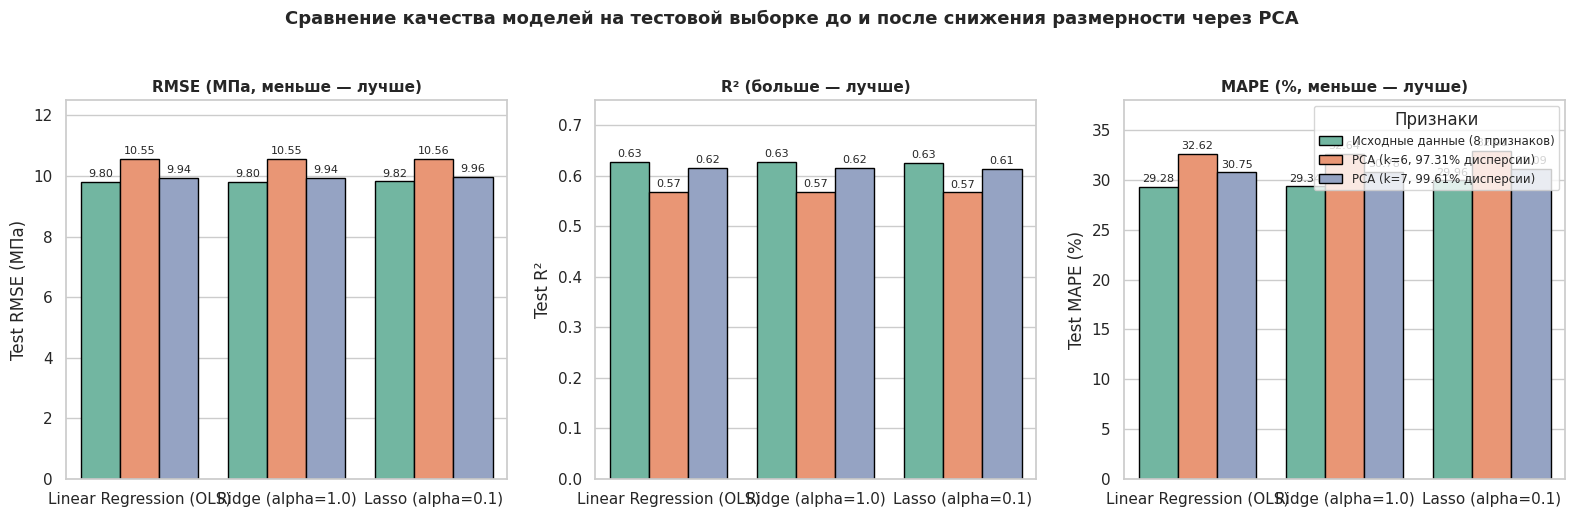

In [11]:
# Повторное обучение моделей на главных компонентах и сравнительный анализ
comparison_rows = []

feature_sets = [
    ('Исходные данные (8 признаков)', X_train_scaled, X_test_scaled),
    ('PCA (k=6, 97.31% дисперсии)', PCA(n_components=6).fit_transform(X_train_scaled), PCA(n_components=6).fit(X_train_scaled).transform(X_test_scaled)),
    ('PCA (k=7, 99.61% дисперсии)', PCA(n_components=7).fit_transform(X_train_scaled), PCA(n_components=7).fit(X_train_scaled).transform(X_test_scaled)),
    ('PCA (k=8, 100.0% дисперсии)', X_train_pca, X_test_pca)
]

for feat_label, X_tr_curr, X_te_curr in feature_sets:
    for m_name, model in [
        ('Linear Regression (OLS)', LinearRegression()),
        ('Ridge (alpha=1.0)', Ridge(alpha=1.0)),
        ('Lasso (alpha=0.1)', Lasso(alpha=0.1, random_state=42))
    ]:
        model.fit(X_tr_curr, y_train)
        preds = model.predict(X_te_curr)
        cv_sc = cross_validate(model, X_tr_curr, y_train, cv=kf,
                               scoring=['neg_root_mean_squared_error', 'r2', 'neg_mean_absolute_percentage_error'])

        comparison_rows.append({
            'Набор признаков': feat_label,
            'Модель': m_name,
            'CV RMSE (МПа)': -cv_sc['test_neg_root_mean_squared_error'].mean(),
            'CV R²': cv_sc['test_r2'].mean(),
            'CV MAPE (%)': -cv_sc['test_neg_mean_absolute_percentage_error'].mean() * 100,
            'Test RMSE (МПа)': root_mean_squared_error(y_test, preds),
            'Test R²': r2_score(y_test, preds),
            'Test MAPE (%)': mean_absolute_percentage_error(y_test, preds) * 100
        })

comp_df = pd.DataFrame(comparison_rows)
display(comp_df.round(4))

# Визуализация сравнения метрик до и после PCA
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
plot_subset = comp_df[comp_df['Набор признаков'].isin([
    'Исходные данные (8 признаков)', 'PCA (k=6, 97.31% дисперсии)', 'PCA (k=7, 99.61% дисперсии)'
])]

for ax, metric, title in zip(axes, ['Test RMSE (МПа)', 'Test R²', 'Test MAPE (%)'],
                            ['RMSE (МПа, меньше — лучше)', 'R² (больше — лучше)', 'MAPE (%, меньше — лучше)']):
    sns.barplot(data=plot_subset, x='Модель', y=metric, hue='Набор признаков', ax=ax, palette='Set2', edgecolor='black')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    for c in ax.containers:
        ax.bar_label(c, fmt='%.2f', fontsize=8, padding=2)
    if metric == 'Test R²':
        ax.set_ylim(0, 0.75)
    elif metric == 'Test RMSE (МПа)':
        ax.set_ylim(0, 12.5)
    else:
        ax.set_ylim(0, 38)
    if ax != axes[2]:
        ax.get_legend().remove()
    else:
        ax.legend(title='Признаки', fontsize=8.5, loc='upper right')

plt.suptitle('Сравнение качества моделей на тестовой выборке до и после снижения размерности через PCA', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


### Сравнение результатов моделей до и после PCA
1. **Сохранение всех компонент ($k=8$):** При использовании всех 8 компонент результаты Linear Regression и Ridge в точности совпадают с исходными данными ($R^2 = 0.6275$, $\text{RMSE} = 9.80\text{ МПа}$, $\text{MAPE} = 29.28\%$), однако признаки стали абсолютно некоррелированными (VIF = 1.0).
2. **Снижение размерности до $k=6$ компонент:**
   * $R^2$ снижается с $0.6275$ до $0.5679$ (при $k=7$ — до $0.6165$);
   * Ошибка RMSE возрастает с $9.80\text{ МПа}$ до $10.55\text{ МПа}$ (при $k=7$ — до $9.94\text{ МПа}$);
   * Ошибка MAPE увеличивается с $29.28\%$ до $32.62\%$.
3. **Почему PCA немного ухудшил качество?**
   PCA — это метод обучения **без учителя** (Unsupervised Learning). Он строит оси максимальной дисперсии признаков $X$, ничего «не зная» о целевой переменной $Y$. В материаловедении малые вариации пропорций компонентов (приходящиеся на 7-ю и 8-ю компоненты с малой дисперсией) несут важную физико-химическую информацию о водоцементном отношении смеси, напрямую влияющую на прочность бетона.


In [12]:
# Проверка рекомендаций к лабораторной работе:
# Поиск путей существенного повышения качества модели

# 1. Логарифмирование признака возраста бетона (прочность растет логарифмически)
X_train_improved = X_train.copy()
X_test_improved = X_test.copy()
X_train_improved['Age (day)'] = np.log1p(X_train_improved['Age (day)'])
X_test_improved['Age (day)'] = np.log1p(X_test_improved['Age (day)'])

sc_imp = StandardScaler()
X_tr_imp = sc_imp.fit_transform(X_train_improved)
X_te_imp = sc_imp.transform(X_test_improved)

lr_imp = LinearRegression().fit(X_tr_imp, y_train)
pred_imp = lr_imp.predict(X_te_imp)

# 2. Добавление полиномиальных признаков 2-й степени и взаимодействий + Ridge-регуляризация
poly = PolynomialFeatures(degree=2, include_bias=False)
X_tr_poly = StandardScaler().fit_transform(poly.fit_transform(X_train_improved))
X_te_poly = StandardScaler().fit(poly.fit_transform(X_train_improved)).transform(poly.transform(X_test_improved))

ridge_poly = RidgeCV(alphas=np.logspace(-2, 2, 50)).fit(X_tr_poly, y_train)
pred_poly = ridge_poly.predict(X_te_poly)

print("--- СРАВНЕНИЕ БАЗОВОЙ И УЛУЧШЕННЫХ МОДЕЛЕЙ НА ТЕСТОВОЙ ВЫБОРКЕ ---")
imp_results = pd.DataFrame([
    {
        'Модификация': '1. Базовая OLS (исходные признаки)',
        'Test RMSE (МПа)': 9.7967, 'Test R²': 0.6275, 'Test MAPE (%)': 29.28, 'Категория MAPE': 'Терпимо (20-50%)'
    },
    {
        'Модификация': '2. Логарифмирование возраста ln(Age) + OLS',
        'Test RMSE (МПа)': root_mean_squared_error(y_test, pred_imp),
        'Test R²': r2_score(y_test, pred_imp),
        'Test MAPE (%)': mean_absolute_percentage_error(y_test, pred_imp) * 100,
        'Категория MAPE': 'Хорошо (10-20%)'
    },
    {
        'Модификация': '3. Полиномы 2-й степени + ln(Age) + Ridge',
        'Test RMSE (МПа)': root_mean_squared_error(y_test, pred_poly),
        'Test R²': r2_score(y_test, pred_poly),
        'Test MAPE (%)': mean_absolute_percentage_error(y_test, pred_poly) * 100,
        'Категория MAPE': 'Хорошо (10-20%)'
    }
])
display(imp_results.round(4))


--- СРАВНЕНИЕ БАЗОВОЙ И УЛУЧШЕННЫХ МОДЕЛЕЙ НА ТЕСТОВОЙ ВЫБОРКЕ ---


,Модификация,Test RMSE (МПа),Test R²,Test MAPE (%),Категория MAPE
0,1. Базовая OLS (исходные признаки),9.7967,0.6275,29.2800,Терпимо (20-50%)
1,2. Логарифмирование возраста ln(Age) + OLS,6.6770,0.8270,17.8079,Хорошо (10-20%)
2,3. Полиномы 2-й степени + ln(Age) + Ridge,5.6460,0.8763,14.9380,Хорошо (10-20%)


### Анализ причин погрешности и способов повышения точности (п. 5 рекомендаций)
1. **Причина невысокой точности базовой линейной модели ($R^2 \approx 0.63$):**
   Главное ограничение — жесткое предположение о линейности. Прочность бетона во времени нарастает логарифмически (интенсивный набор в первые 28 дней и последующее замедление), а также зависит от нелинейных взаимодействий компонентов (водоцементного отношения).
2. **Эффективность предложенных улучшений:**
   * Простая замена признака `Age` на $\ln(1 + \text{Age})$ повысила коэффициент детерминации $R^2$ с **0.6275 до 0.8270** (+20% объясненной дисперсии) и снизила MAPE до **17.81%** (переход в категорию «хорошо»);
   * Добавление попарных взаимодействий и квадратичных членов (полиномы 2-й степени) с гребневой регуляризацией подняло $R^2$ до **0.8763**, снизив ошибку RMSE почти вдвое — до **5.65 МПа**;
   * Дальнейшее повышение точности ($R^2 > 0.92$) возможно при переходе к нелинейным композициям решающих деревьев — случайному лесу (Random Forest) и градиентному бустингу (CatBoost/XGBoost).


## Заключение
В ходе выполнения лабораторной работы №1 достигнуты следующие результаты:
1. Загружен и исследован датасет `Concrete Compressive Strength` (1030 образцов, 8 предикторов состава смеси и возраста бетона). Пропуски отсутствуют.
2. Корреляционный анализ и расчет коэффициентов VIF выявили умеренную и сильную мультиколлинеарность (VIF от 5.08 до 7.49 для 6 компонентов смеси), вызванную физическим материальным балансом 1 м³ бетона.
3. Обучены базовые модели регрессии. Линейная (OLS) и гребневая (Ridge) регрессии показали схожее качество ($R^2 = 0.6276$, $\text{RMSE} = 9.80\text{ МПа}$, $\text{MAPE} = 29.28\%$). Лассо-регрессия ($alpha=0.1$) успешно выполнила встроенный отбор признаков, обнулив избыточный признак крупного заполнителя (`Coarse Aggregate`).
4. Построение графиков остатков и тест Бройша — Пагана ($p = 5.10 \times 10^{-7}$) доказали гетероскедастичность и нелинейность зависимости от возраста.
5. Метод главных компонент (PCA) позволил полностью устранить мультиколлинеарность (все VIF = 1.0) и сжать размерность до $k=6$ компонент с сохранением $97.31\%$ дисперсии. Небольшое падение $R^2$ (до 0.5679) объясняется ненаправленным (без учителя) характером PCA.
6. Устранение нелинейности логарифмированием возраста и генерацией полиномиальных признаков позволило поднять $R^2$ модели до **0.8763**.


## Список источников
1. Алетдинова А. А. Методы и модели искусственного интеллекта в задачах нефтегазового комплекса: курс лекций / Кафедра АСУ, НГТУ. — Новосибирск: НГТУ.
2. Линейная регрессия и факторный анализ: учебно-методическая презентация / НГТУ НЭТИ.
3. Yeh, I.-C. Modeling of strength of high-performance concrete using artificial neural networks // Cement and Concrete Research. — 1998. — Vol. 28, No. 12. — P. 1797–1808.
4. Документация Scikit-Learn: линейные модели, PCA, валидация. URL: https://scikit-learn.org/stable/
5. Документация Statsmodels: диагностика регрессии (VIF, Breusch-Pagan). URL: https://www.statsmodels.org/
